In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
# ==========================================
# 1. DATA COLLECTION SIMULATION & INGESTION
# ==========================================
# Ingest the logistics dataset CSV file
df = pd.read_csv('Task2_dataset(outliers).csv')
print("--- Initial Dataset Info ---")
print("Dataset Shape:", df.shape)
print(df.head())

--- Initial Dataset Info ---
Dataset Shape: (100, 5)
   Order ID  Distance (km)  Cargo Weight (kg)  Traffic Delay (mins)  \
0      1001          14.36               3.18                    45   
1      1002          33.37               8.36                    20   
2      1003          26.16              13.16                    45   
3      1004          21.76              11.12                    10   
4      1005           7.15              12.20                    10   

   Delivery Time (mins)  
0                 88.99  
1                108.82  
2                112.83  
3                105.25  
4                 67.48  


In [11]:
# ==========================================
# 2. DATA CLEANING & MISSING VALUE AUDIT
# ==========================================
# Check for missing values across all columns
print("\n--- Missing Values Audit ---")
missing_values = df.isnull().sum()
print(missing_values)

# Check and remove duplicate rows if any exist
initial_row_count = len(df)
df = df.drop_duplicates()
print(f"Duplicate rows removed: {initial_row_count - len(df)}")



--- Missing Values Audit ---
Order ID                0
Distance (km)           0
Cargo Weight (kg)       0
Traffic Delay (mins)    0
Delivery Time (mins)    0
dtype: int64
Duplicate rows removed: 0


In [12]:
# ==========================================
# 3. OUTLIER DETECTION & CAPPING (IQR METHOD)
# ==========================================
# Identify and cap extreme outliers using Interquartile Range (IQR)
outlier_columns = ['Distance (km)', 'Cargo Weight (kg)', 'Delivery Time (mins)']
print("\n--- Outlier Detection & Capping ---")

for col in outlier_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Count outliers before clipping
    outliers_count = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    print(f"Outliers detected & capped in '{col}': {outliers_count}")
    
    # Clip extreme values to acceptable bounds
    df[col] = np.clip(df[col], lower_bound, upper_bound)




--- Outlier Detection & Capping ---
Outliers detected & capped in 'Distance (km)': 0
Outliers detected & capped in 'Cargo Weight (kg)': 0
Outliers detected & capped in 'Delivery Time (mins)': 0


In [13]:
# ==========================================
# 4. FEATURE NORMALIZATION (MIN-MAX SCALING)
# ==========================================
# Scale numerical features to a standard range of [0, 1] for machine learning readiness
normalized_df = (df - df.min()) / (df.max() - df.min())
print("\n--- Normalized Data Sample (Min-Max Scaling) ---")
print(normalized_df.head())

# Save the cleaned dataset for downstream modeling / Tableau / Power BI
df.to_csv('cleaned_logistics_dataset.csv', index=False)
print("\nPreprocessing pipeline executed successfully. Cleaned dataset saved!")




--- Normalized Data Sample (Min-Max Scaling) ---
   Order ID  Distance (km)  Cargo Weight (kg)  Traffic Delay (mins)  \
0  0.000000       0.270015           0.059625              0.750000   
1  0.010101       0.731198           0.353776              0.333333   
2  0.020202       0.556283           0.626349              0.750000   
3  0.030303       0.449539           0.510505              0.166667   
4  0.040404       0.095099           0.571834              0.166667   

   Delivery Time (mins)  
0              0.236658  
1              0.365407  
2              0.391443  
3              0.342228  
4              0.097000  

Preprocessing pipeline executed successfully. Cleaned dataset saved!


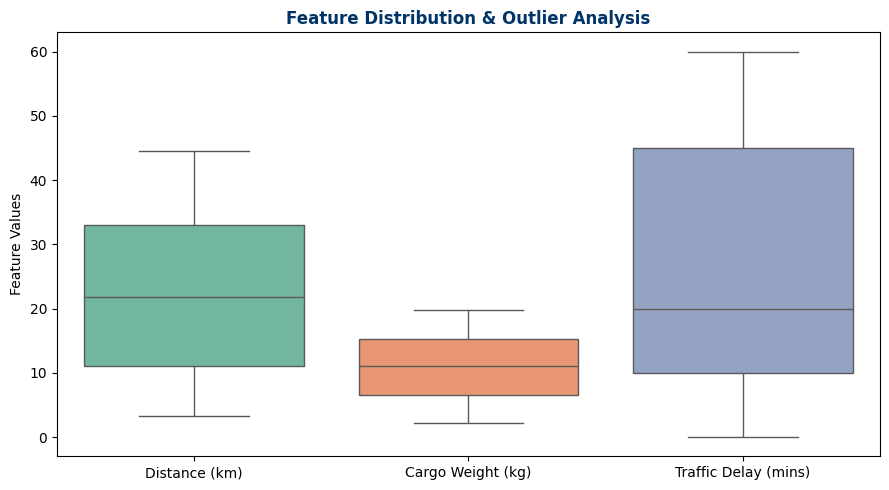

In [14]:
# ==========================================
# 5. VISUALIZATION (DISTRIBUTION & OUTLIERS)
# ==========================================
plt.figure(figsize=(9, 5))
sns.boxplot(data=df[['Distance (km)', 'Cargo Weight (kg)', 'Traffic Delay (mins)']], palette='Set2')
plt.title('Feature Distribution & Outlier Analysis', fontsize=12, fontweight='bold', color='#003366')
plt.ylabel('Feature Values', fontsize=10)
plt.tight_layout()
plt.savefig('preprocessing_boxplot.png', dpi=300)
plt.show()